# Carriers: the dental example

Instance from `data/generator/dental-carriers-example.json` (carrier generator, `math/21_instance-generator.md` §4a;
model in `math/03_loads.md`). Every order has one secondary part, printed on a build plate, with one telescope per
primary part; the primary parts of several orders are milled from one blank (a second carrier kind). A plate holds
up to 12 telescopes, a print run up to 4 plates (given by the emulated nesting, in due-date order), an oven run up to
3 plates (p-batch, grouped by the planner), a blank up to 16 primary parts (emulated in the same order).
**The durations and the blank capacity are placeholders, not Fidentis data.**

Route of every order:
- primary parts: design → blank milling (run per blank: setup, milling, removal on a mill) → separation from the
  blank (per blank, bench) → polishing (per order, n × p, bench);
- secondary part: design → print (run: setup, print, removal on one printer) → oven (up to 3 plates per run, fixed
  program time) → carrier milling (run per plate on the same mills, time per telescope) → QM (per plate, waits for
  the polished primary parts of its orders) → saw;
- then finish (waits for all its plates). The bench stands in for the workers (`math/04`, not modeled yet).

In [1]:
%matplotlib inline
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt

import simulation
from simulation.carrier_generator import CarrierGeneratorParams, generate_carrier_instance
from simulation.check.feasibility import check_schedule
from simulation.control.rescheduling import ReschedulingPolicy, execute
from simulation.due_dates import assign_due_dates
from simulation.io.json_loader import read_model
from simulation.metrics import run_metrics
from simulation.model.compiled import compile_instance
from simulation.objectives import MAKESPAN, TARDY_ORDERS, TOTAL_TARDINESS, lexicographic
from simulation.planners.cpsat import cpsat_planner, solve
from simulation.planners.dispatching import best_dispatch
from simulation.sim.scenario import sample_scenario
from simulation.viz import plot_carriers, plot_gantt

DATA = Path(simulation.__file__).parents[2] / "data"
params = read_model(DATA / "generator" / "dental-carriers-example.json", CarrierGeneratorParams)
inst = generate_carrier_instance(params)  # nesting in the order of the generator's due dates (lead-time bound)
# due dates relative to the best dispatching plan (theta 1, 1.2, 1.5; math/06): that plan is on time, tardiness
# comes from disturbances or weaker plans. The lead-time bound ignores the oven queue and is unreachable here.
_, reference = best_dispatch(compile_instance(inst))
inst = assign_due_dates(inst, (1.0, 1.2, 1.5), seed=0, reference=reference)
ci = compile_instance(inst)
telescopes = {o.id: sum(p.type == "primary" for p in o.parts) for o in inst.orders}
plates = [c for c in inst.carriers if c.id.startswith("C")]
blanks = [c for c in inst.carriers if c.id.startswith("B")]
print(f"{len(inst.orders)} orders, {len(plates)} plates, {len(blanks)} blanks, {len(inst.runs)} print runs, "
      f"{ci.n_ops} operations, {len(inst.machines)} machines")

40 orders, 19 plates, 11 blanks, 5 print runs, 293 operations, 14 machines


## Nesting: plates, blanks and loads

Top: one row per plate, grouped by print run (the run's load, separated by lines); one segment per order, width =
telescopes of its secondary part; dashed line: capacity 12. Below it the print duration of each run from the
estimator (fixed 20 + 0.5 × summed part times, clamped to [longest part, sum]). Bottom: one row per blank (no given
runs: every blank is its own mill run), one segment per order, width = its primary parts on that blank; dashed line:
capacity 16.

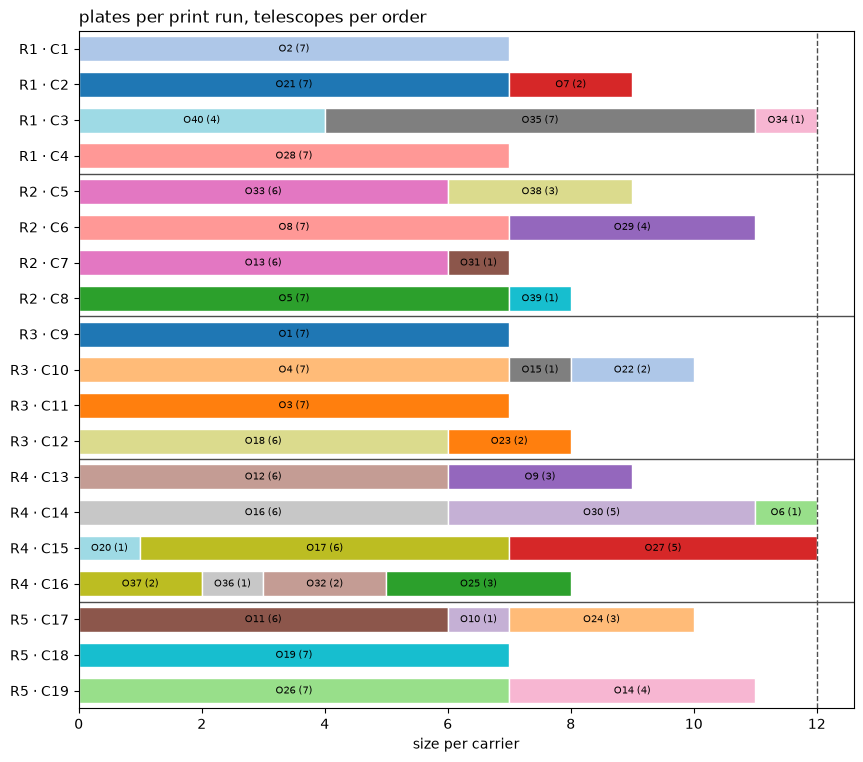

R1: plates C1, C2, C3, C4 · 35 telescopes · print {160} min
R2: plates C5, C6, C7, C8 · 35 telescopes · print {160} min
R3: plates C9, C10, C11, C12 · 32 telescopes · print {148} min
R4: plates C13, C14, C15, C16 · 41 telescopes · print {184} min
R5: plates C17, C18, C19 · 28 telescopes · print {132} min


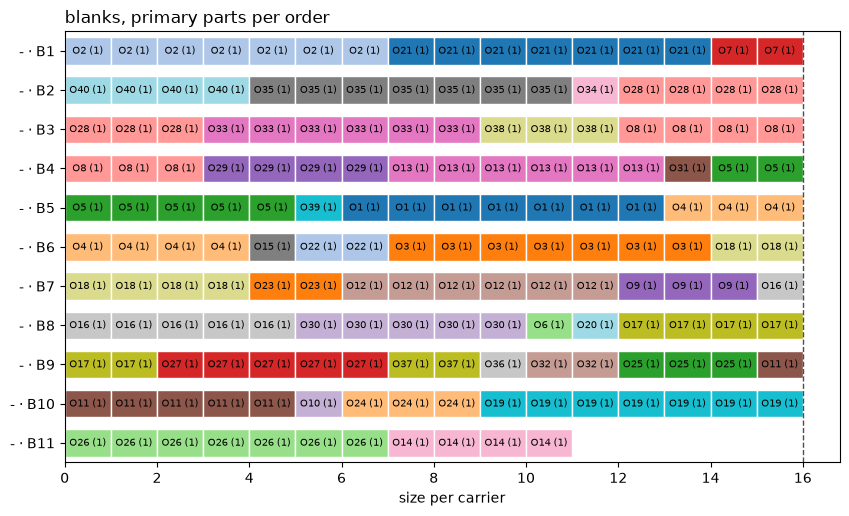

In [2]:
plot_carriers(inst.model_copy(update={"carriers": plates}), size=lambda k, _part: telescopes[k],
              capacity=params.carrier_capacity, title="plates per print run, telescopes per order")
plt.show()
for r in inst.runs:
    load = sum(telescopes[k] for c in plates if c.id in r.carriers for k, _ in c.parts)
    print_time = dict(ci.options[ci.op_index[r.id, "print"]])
    print(f"{r.id}: plates {', '.join(r.carriers)} · {load} telescopes · print {set(print_time.values())} min")
plot_carriers(inst.model_copy(update={"carriers": blanks}), capacity=params.blank_capacity,
              title="blanks, primary parts per order")
plt.show()

## Plan

Best dispatching rule and CP-SAT (60 s, warm start from the rule, one worker) for the makespan, and CP-SAT with
total tardiness first and makespan second. Gantt chart of the lexicographic plan: order operations colored by
order, carrier operations (separation, oven, QM, saw) light grey, run operations (setup, print or milling, removal)
dark grey; one bar per oven run, labeled with its plates. Below: the loads of the oven runs.

In [3]:
rule, rule_plan = best_dispatch(ci)
cp = solve(ci, time_limit=60, workers=1, hint=rule_plan)
TARDINESS_FIRST = lexicographic(TOTAL_TARDINESS, MAKESPAN)
cp_lex = solve(ci, TARDINESS_FIRST, time_limit=60, workers=1, hint=best_dispatch(ci, TARDINESS_FIRST)[1])
print(f"{'plan':28} {'status':>8} {'Cmax':>6} {'sum T':>6} {'tardy':>6} {'violations':>11}")
for name, status, plan in [(f"best rule ({rule})", "", rule_plan), ("CP-SAT makespan", cp.status, cp.schedule),
                           ("CP-SAT tardiness>makespan", cp_lex.status, cp_lex.schedule)]:
    print(f"{name:28} {status:>8} {MAKESPAN.evaluate(ci, plan):>6} {TOTAL_TARDINESS.evaluate(ci, plan):>6}"
          f" {TARDY_ORDERS.evaluate(ci, plan):>6} {len(check_schedule(ci, plan)):>11}")

plan                           status   Cmax  sum T  tardy  violations
best rule (lrp/joint)                   1138      0      0           0
CP-SAT makespan              FEASIBLE   1138      0      0           0
CP-SAT tardiness>makespan    FEASIBLE   1138      0      0           0


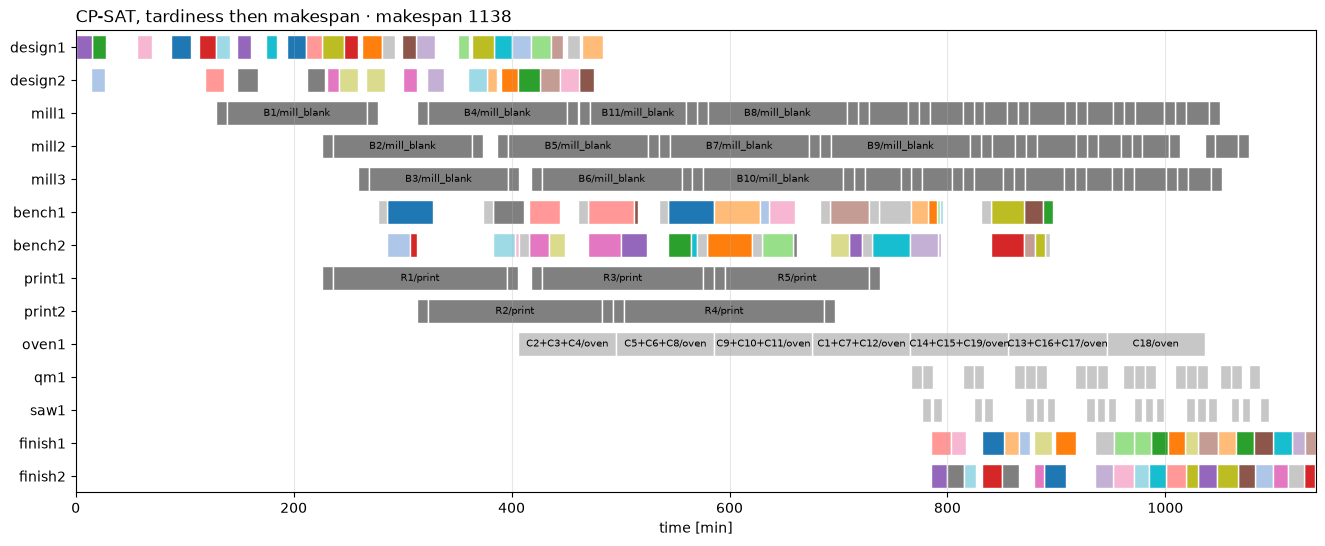

oven1 at   406: C2 + C3 + C4
oven1 at   496: C5 + C6 + C8
oven1 at   586: C10 + C11 + C9
oven1 at   676: C1 + C12 + C7
oven1 at   766: C14 + C15 + C19
oven1 at   856: C13 + C16 + C17
oven1 at   946: C18


In [4]:
plot_gantt(ci, cp_lex.schedule, title=f"CP-SAT, tardiness then makespan · makespan {MAKESPAN.evaluate(ci, cp_lex.schedule)}")
plt.gcf().set_size_inches(16, 6)
plt.show()
oven_runs: dict[tuple[str, int], list[str]] = {}
for a in sorted(cp_lex.schedule, key=lambda a: (a.start, a.order_id)):
    if a.op_id == "oven":
        oven_runs.setdefault((a.machine, a.start), []).append(a.order_id)
for (machine, start), carriers in oven_runs.items():
    print(f"{machine} at {start:>5}: {' + '.join(carriers)}")

## Execution under disturbances

Durations log-normal ($\sigma = 0.3$), start offsets ($q = 0.5$, $a = b = 5$), seeds 0–4. Start plan: the
lexicographic CP-SAT plan. Policies: no planning tool, repair only, complete rescheduling with CP-SAT (tardiness
first, 2 s per call) triggered by $\delta_C = 10$, $\delta_S = 30$ and a safety net every 120 minutes. Means over the
seeds; one run, no statistical test.

In [5]:
plan = cp_lex.schedule
scenarios = [sample_scenario(inst, sigma=0.3, seed=seed, q=0.5, max_early=5, max_late=5) for seed in range(5)]
policies = {
    "no planning tool": None,
    "repair only": ReschedulingPolicy(),
    "CP-SAT rescheduling": ReschedulingPolicy(cpsat_planner(time_limit=2, objective=TARDINESS_FIRST),
                                              max_makespan_change=10, max_shift=30, period=120),
}
print(f"{'policy':22} {'Cmax':>7} {'F':>7} {'sum T':>7} {'tardy':>6} {'D_M':>5} {'N_C':>5} {'feasible':>9}")
for name, policy in policies.items():
    results = [execute(ci, plan, s, policy) for s in scenarios]
    rows = [run_metrics(ci, plan, r) for r in results]
    ok = all({v.constraint for v in check_schedule(ci, r.schedule)} <= {"C2"} for r in results)
    avg = {key: mean(r[key] for r in rows) for key in rows[0]}
    print(f"{name:22} {avg['makespan']:>7.1f} {avg['mean_flow_time']:>7.1f} {avg['total_tardiness']:>7.1f}"
          f" {avg['tardy_orders']:>6.1f} {avg['machine_changes']:>5.1f} {avg['reschedulings']:>5.1f} {str(ok):>9}")

policy                    Cmax       F   sum T  tardy   D_M   N_C  feasible
no planning tool        1272.4   811.0  1383.0   15.6   0.0   0.0      True


repair only             1272.2   807.6  1364.0   14.8   0.0   0.0      True


CP-SAT rescheduling     1248.2   757.1   643.6    9.2  71.6  19.8      True


**Observations** (one instance, 5 seeds, placeholder durations and blank capacity; own computation, no statistical
test):

- **The mills become a second bottleneck next to the oven:** they mill 11 blanks (long runs, up to 16 parts each) and
  then 19 plates (short runs, time per telescope); with blank milling first, carrier milling only starts around 780,
  so the QMs start late and the mills run until about 1050. The oven still runs its 7 batches without gap.
- **Makespan 1138** for the best rule, and CP-SAT does not improve it within 60 s (293 operations instead of 180;
  status FEASIBLE, no proof). The earlier version without blanks and carrier milling (978) is not comparable: the
  route and the random instance changed.
- **All plans are on time** because the due dates are calibrated with the best rule plan (theta >= 1).
- **Under disturbances** CP-SAT rescheduling halves the total tardiness (1364 with repair only, 644) and lowers the
  late orders from 14.8 to 9.2, at 19.8 reschedulings per run; repair alone changes almost nothing.